(sec-7-1)=
# 7.1 Random Processes

Two ECG recordings from the same person will not match sample for sample. The heart rate changes, the electrodes move slightly, and the noise changes too. Rather than predicting every value, we often want to describe typical behavior: the average level, the amount of variation, or how nearby samples are related.

A random process gives us a mathematical way to do that. I will begin by separating two views that are easy to mix up: looking across many possible recordings, and looking along one recording in time. We will use simulations and physiological signals to see when these views tell a similar story.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mne

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
mne.set_log_level("ERROR")
rng = np.random.default_rng(42)

(sec-7-1-1)=
## 7.1.1 Two Views of a Random Process: the Ensemble and the Time Axis

A discrete-time random process $x[n]$ is a rule that assigns a whole sequence to every outcome $\xi$ of a random experiment. Writing the outcome explicitly, $x[n, \xi]$ is a function of two arguments, and we can freeze either one of them.

- **Freeze the outcome $\xi$.** We get one ordinary sequence $x[n, \xi_1]$, called a **realization** or sample path. Every recording we ever analyze is a single realization.
- **Freeze the time $n_0$.** We get a single random variable $x[n_0]$, whose value differs from realization to realization. It has a probability density, a mean and a variance like any random variable from [Section 2.4](../ch02_math_toolkit/05_probability_and_statistics.ipynb).

The collection of all realizations is the **ensemble**. A good mental picture is a stack of recordings from a thousand identical subjects (or a thousand repetitions on the same subject under identical conditions), aligned in time. Reading *down* the stack at a fixed instant is the ensemble view; reading *along* one recording is the time view. Most of the theory is written in the ensemble view, because expectations are ensemble averages. Most of the practice happens in the time view, because we usually have one recording. Ergodicity, in [Section 7.1.4](#sec-7-1-4), is the bridge between them.

To make this concrete we simulate a toy "occipital EEG": a 10 Hz alpha oscillation of amplitude $A = 20$ µV whose phase $\Phi$ is random (uniform on $[0, 2\pi)$, because the rhythm has no reason to start at any particular phase when we press "record"), plus Gaussian background activity with standard deviation $\sigma_w = 8$ µV:

$$
x[n] = A\cos(\Omega_0 n + \Phi) + w[n], \qquad \Omega_0 = 2\pi \cdot \frac{10}{160}\ \text{rad/sample}.
$$

In this model, $n$ marks time, $A$ sets the oscillation amplitude, $\Phi$ is a randomly chosen phase, and $w[n]$ is the added noise. One draw of the phase and noise gives one possible recording, called a realization. Drawing them again gives another. An average across realizations holds $n$ fixed; a time average moves along one realization. They are different operations, even when assumptions allow them to estimate the same quantity.

In [2]:
fs = 160.0                     # Hz, the EEG sampling rate used later in this section
f0, A, sigma_w = 10.0, 20.0, 8.0
Omega0 = 2 * np.pi * f0 / fs
n = np.arange(int(1.0 * fs))   # one second per realization


def alpha_realizations(n_real, n, rng):
    """Draw realizations of A cos(Omega0 n + Phi) + w[n] (rows = realizations)."""
    phi = rng.uniform(0, 2 * np.pi, size=(n_real, 1))
    noise = rng.normal(0, sigma_w, size=(n_real, n.size))
    return A * np.cos(Omega0 * n + phi) + noise


ensemble = alpha_realizations(5000, n, rng)
n0 = 40                                               # the instant t0 = 0.25 s
long_record = alpha_realizations(1, np.arange(int(300 * fs)), rng)[0]

print(f"Ensemble at n0: mean = {ensemble[:, n0].mean():6.2f} uV, std = {ensemble[:, n0].std():5.2f} uV")
print(f"One 300 s record: mean = {long_record.mean():6.2f} uV, std = {long_record.std():5.2f} uV")
print(f"Theory: mean = 0, std = sqrt(A^2/2 + sigma_w^2) = {np.sqrt(A**2 / 2 + sigma_w**2):.2f} uV")

Ensemble at n0: mean =   0.02 uV, std = 16.14 uV
One 300 s record: mean =  -0.06 uV, std = 16.29 uV
Theory: mean = 0, std = sqrt(A^2/2 + sigma_w^2) = 16.25 uV


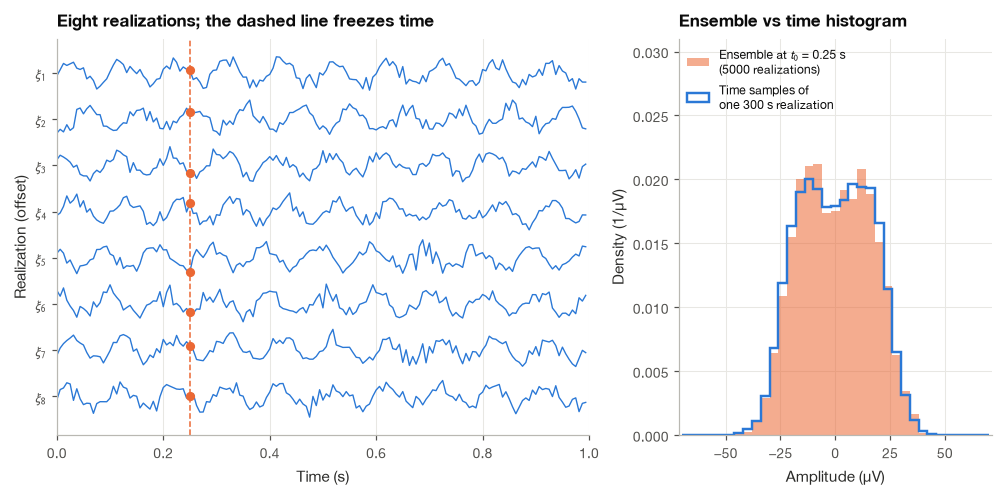

In [3]:
fig = plt.figure(figsize=(9, 4.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.7, 1])
ax = fig.add_subplot(gs[0])
t = n / fs
offset = 90
for i in range(8):
    ax.plot(t, ensemble[i] - i * offset, color=C[0], lw=0.9)
    ax.plot(t[n0], ensemble[i, n0] - i * offset, "o", color=C[1], ms=5)
ax.axvline(t[n0], color=C[1], lw=1, ls="--")
ax.set_yticks(-offset * np.arange(8), [f"$\\xi_{i + 1}$" for i in range(8)])
ax.set(xlabel="Time (s)", ylabel="Realization (offset)", xlim=(0, 1),
       title="Eight realizations; the dashed line freezes time")
ax.grid(axis="y", visible=False)

ax = fig.add_subplot(gs[1])
bins = np.linspace(-70, 70, 36)
ax.hist(ensemble[:, n0], bins=bins, density=True, color=C[1], alpha=0.55,
        label=f"Ensemble at $t_0$ = {t[n0]:.2f} s\n(5000 realizations)")
ax.hist(long_record, bins=bins, density=True, histtype="step", color=C[0], lw=1.6,
        label="Time samples of\none 300 s realization")
ax.set(xlabel="Amplitude (µV)", ylabel="Density (1/µV)", title="Ensemble vs time histogram", ylim=(0, 0.031))
ax.legend(loc="upper left", fontsize=8)
plt.show()

The orange histogram is built from 5000 different realizations at one instant; the blue outline is built from 48,000 consecutive samples of a single realization. They agree, with the double-humped shape of a sinusoid with random phase smoothed by Gaussian noise. This agreement is not automatic, and [Section 7.1.4](#sec-7-1-4) shows a process where it fails.

(sec-7-1-2)=
## 7.1.2 Mean and Autocorrelation Functions

A complete description of a random process would list the joint probability density of $x[n_1], x[n_2], \ldots, x[n_k]$ for every choice of $k$ instants. That is far more than we can ever estimate from data. In signal processing we almost always settle for the first two moments.

The **mean function** is the ensemble average at each instant,

(eq-7-1)=
\begin{equation*}
\mu_x[n] = \mathbb{E}\{x[n]\}. \tag{7.1}
\end{equation*}

The **autocorrelation function** measures how strongly values at two instants are related,

(eq-7-2)=
\begin{equation*}
R_x[n_1, n_2] = \mathbb{E}\{x[n_1]\,x[n_2]\}, \tag{7.2}
\end{equation*}

and the **autocovariance** is the same quantity after removing the means, $C_x[n_1, n_2] = R_x[n_1, n_2] - \mu_x[n_1]\mu_x[n_2]$. Setting $n_1 = n_2 = n$ gives $R_x[n, n] = \mathbb{E}\{x^2[n]\}$, the mean power at time $n$, and $C_x[n, n] = \sigma_x^2[n]$, the variance. For real signals these are expectations over the ensemble, not sums over time; the time-averaged autocorrelation of Section 6.1 is a different object, and the conditions under which the two coincide are the subject of Section 7.1.4.

**Example 7.1.1.** Find the mean and autocorrelation of the random-phase sinusoid $s[n] = A\cos(\Omega_0 n + \Phi)$ with $\Phi$ uniform on $[0, 2\pi)$.

**Step 1: the mean.** The expectation over $\Phi$ is an integral against its density $1/(2\pi)$:

$$
\mu_s[n] = \int_0^{2\pi} A\cos(\Omega_0 n + \phi)\,\frac{d\phi}{2\pi} = 0,
$$

because a cosine integrated over a full period of its argument vanishes, whatever the offset $\Omega_0 n$.

**Step 2: the product.** Using $\cos\alpha\cos\beta = \tfrac{1}{2}[\cos(\alpha - \beta) + \cos(\alpha + \beta)]$ with $\alpha = \Omega_0 n_2 + \Phi$ and $\beta = \Omega_0 n_1 + \Phi$,

$$
s[n_1]\,s[n_2] = \frac{A^2}{2}\Big[\cos\big(\Omega_0 (n_2 - n_1)\big) + \cos\big(\Omega_0 (n_1 + n_2) + 2\Phi\big)\Big].
$$

**Step 3: take the expectation.** The first term does not depend on $\Phi$ and passes through unchanged. The second term is a cosine of $2\Phi$ plus a constant, and averaging it over a uniform $\Phi$ gives zero for the same reason as in Step 1. With $k = n_2 - n_1$,

(eq-7-3)=
\begin{equation*}
R_s[n_1, n_2] = \frac{A^2}{2}\cos(\Omega_0 k). \tag{7.3}
\end{equation*}

The autocorrelation depends only on the separation $k$ between the two instants and not on where they sit in time. Adding independent zero-mean noise $w[n]$ with variance $\sigma_w^2$, whose values at different instants are uncorrelated, adds $\sigma_w^2$ at $k = 0$ only (the cross terms $\mathbb{E}\{s[n_1]w[n_2]\}$ vanish because the two are independent and $w$ has zero mean). We can check equation [(7.3)](#eq-7-3) by averaging down the ensemble from the previous cell.

In [4]:
n1 = 40
for k in [0, 1, 4, 8, 16]:
    R_ensemble = np.mean(ensemble[:, n1] * ensemble[:, n1 + k])
    R_theory = A**2 / 2 * np.cos(Omega0 * k) + sigma_w**2 * (k == 0)
    print(f"k = {k:2d}: ensemble average = {R_ensemble:8.2f} uV^2, theory = {R_theory:8.2f} uV^2")

k =  0: ensemble average =   260.50 uV^2, theory =   264.00 uV^2
k =  1: ensemble average =   182.24 uV^2, theory =   184.78 uV^2
k =  4: ensemble average =    -0.08 uV^2, theory =     0.00 uV^2
k =  8: ensemble average =  -197.22 uV^2, theory =  -200.00 uV^2
k = 16: ensemble average =   196.27 uV^2, theory =   200.00 uV^2


The agreement is within a few percent, which is the expected scatter of an average over 5000 realizations. At $k = 8$ samples the two instants are half an alpha period apart (50 ms) and the correlation is strongly negative: if the rhythm is at a peak now, it is probably at a trough 50 ms later.

(sec-7-1-3)=
## 7.1.3 Stationarity

A process is **strict-sense stationary** (SSS) when all of its statistical properties are invariant to a shift of the time origin: for every $k$, every set of instants and every shift $m$, the joint density of $x[n_1], \ldots, x[n_k]$ equals that of $x[n_1 + m], \ldots, x[n_k + m]$. Pressing "record" a minute later gives a statistically indistinguishable recording.

Strict stationarity is hard to verify and stronger than we usually need. A process is **wide-sense stationary** (WSS) when only its first two moments are shift invariant:

(eq-7-4)=
\begin{equation*}
\mu_x[n] = \mu_x \ \text{(a constant)}, \qquad R_x[n, n + k] = R_x[k] \ \text{(a function of the lag only)}. \tag{7.4}
\end{equation*}

The random-phase sinusoid of Example 7.1.1 is WSS. From now on, when I write $R_x[k]$ with a single argument, wide-sense stationarity is assumed.

### Three properties of the autocorrelation of a WSS process

1. **Power at lag zero.** $R_x[0] = \mathbb{E}\{x^2[n]\}$ is the mean power of the process, and it is the same at every instant.
2. **Even symmetry.** $R_x[-k] = \mathbb{E}\{x[n]x[n-k]\}$. Substituting $m = n - k$ gives $\mathbb{E}\{x[m + k]x[m]\} = R_x[k]$, so $R_x[-k] = R_x[k]$.
3. **Maximum at zero.** $|R_x[k]| \le R_x[0]$. To see why, note that the expected square of any real quantity is non-negative:

$$
\begin{aligned}
0 \le \mathbb{E}\big\{(x[n] \pm x[n+k])^2\big\}
&= \mathbb{E}\{x^2[n]\} \pm 2\,\mathbb{E}\{x[n]x[n+k]\} + \mathbb{E}\{x^2[n+k]\} \\
&= 2R_x[0] \pm 2R_x[k].
\end{aligned}
$$

Taking the plus sign gives $R_x[k] \ge -R_x[0]$ and the minus sign gives $R_x[k] \le R_x[0]$. No lag can be more similar to the present than the present itself.

### A process that is not stationary: the random walk

Accumulate independent zero-mean steps $w[n]$ of variance $\sigma^2$, starting from $s[0] = 0$:

$$
s[n] = s[n-1] + w[n] = \sum_{i=1}^{n} w[i].
$$

The mean is zero at every $n$, so the first condition in [(7.4)](#eq-7-4) holds. The variance does not stay constant. Because the steps are independent, the variance of their sum is the sum of their variances,

(eq-7-5)=
\begin{equation*}
\sigma_s^2[n] = \operatorname{Var}\Big\{\sum_{i=1}^{n} w[i]\Big\} = \sum_{i=1}^{n} \operatorname{Var}\{w[i]\} = n\sigma^2, \tag{7.5}
\end{equation*}

which grows without bound. The spread of the ensemble widens like $\sqrt{n}$. I mention the random walk because slow electrode drift and some forms of baseline wander behave like it over short stretches: the longer you wait, the further the baseline may have wandered, and statistics computed early in a recording do not describe its end.

In [5]:
n_walk = np.arange(1, 801)
steps = rng.normal(0, 1.0, size=(2000, n_walk.size))
walks = np.cumsum(steps, axis=1)
var_walk = walks.var(axis=0)
for n_check in [100, 400, 800]:
    print(f"n = {n_check:3d}: ensemble variance = {var_walk[n_check - 1]:6.1f}, theory n*sigma^2 = {n_check}")

n = 100: ensemble variance =   99.6, theory n*sigma^2 = 100
n = 400: ensemble variance =  394.0, theory n*sigma^2 = 400
n = 800: ensemble variance =  744.9, theory n*sigma^2 = 800


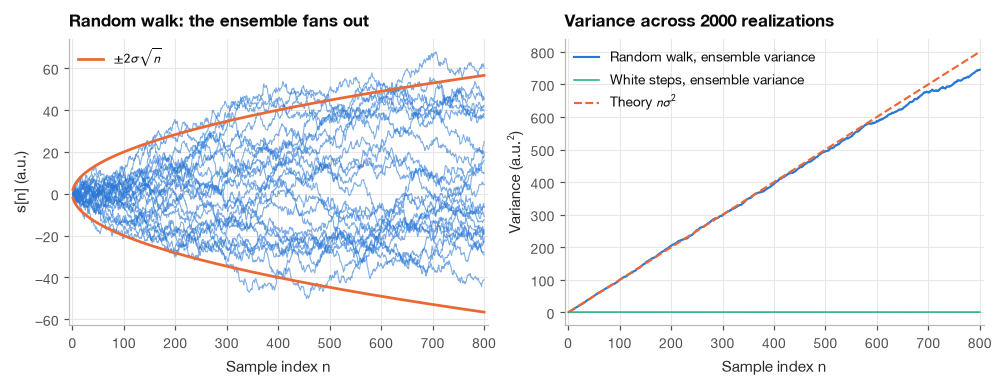

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
ax = axes[0]
for i in range(25):
    ax.plot(n_walk, walks[i], color=C[0], lw=0.7, alpha=0.6)
ax.plot(n_walk, 2 * np.sqrt(n_walk), color=C[1], lw=1.8, label=r"$\pm 2\sigma\sqrt{n}$")
ax.plot(n_walk, -2 * np.sqrt(n_walk), color=C[1], lw=1.8)
ax.set(xlabel="Sample index n", ylabel="s[n] (a.u.)", title="Random walk: the ensemble fans out")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(n_walk, var_walk, color=C[0], label="Random walk, ensemble variance")
ax.plot(n_walk, steps.var(axis=0), color=C[2], lw=1.0, label="White steps, ensemble variance")
ax.plot(n_walk, n_walk, color=C[1], ls="--", lw=1.4, label=r"Theory $n\sigma^2$")
ax.set(xlabel="Sample index n", ylabel="Variance (a.u.$^2$)", title="Variance across 2000 realizations")
ax.legend(loc="upper left")
plt.show()

(sec-7-1-4)=
## 7.1.4 Ergodicity: When One Recording Is Enough

Expectations are ensemble averages, but a clinician has one ECG from one patient, not a thousand. Whenever we compute a mean or an autocorrelation from a single recording, we are silently replacing an ensemble average by a time average. A process for which this replacement is justified is called **ergodic** (for the statistic in question).

Take the simplest statistic, the mean. The time average of $N$ samples of one realization is

$$
\hat{\mu}_N = \frac{1}{N}\sum_{n=0}^{N-1} x[n].
$$

For a WSS process its expectation is $\mu_x$, because expectation is linear. The question is whether its variance shrinks to zero as $N$ grows, so that every realization gives the same answer in the limit.

**Step 1: expand the variance as a double sum.** Writing $\hat{\mu}_N - \mu_x = \frac{1}{N}\sum_n (x[n] - \mu_x)$ and squaring,

$$
\operatorname{Var}\{\hat{\mu}_N\} = \frac{1}{N^2}\sum_{n=0}^{N-1}\sum_{m=0}^{N-1} \mathbb{E}\{(x[n] - \mu_x)(x[m] - \mu_x)\} = \frac{1}{N^2}\sum_{n=0}^{N-1}\sum_{m=0}^{N-1} C_x[n - m].
$$

**Step 2: group the terms by lag.** The summand depends only on $k = n - m$. In the $N \times N$ grid of index pairs, the diagonal $k = 0$ holds $N$ pairs, the diagonals $k = \pm 1$ hold $N - 1$ pairs each, and in general lag $k$ appears $N - |k|$ times. Hence

(eq-7-6)=
\begin{equation*}
\operatorname{Var}\{\hat{\mu}_N\} = \frac{1}{N}\sum_{k=-(N-1)}^{N-1}\left(1 - \frac{|k|}{N}\right) C_x[k]. \tag{7.6}
\end{equation*}

**Step 3: read off the condition.** If the autocovariance decays to zero fast enough that $\sum_k |C_x[k]|$ is finite, the sum in [(7.6)](#eq-7-6) stays bounded and the factor $1/N$ drives the variance to zero. The process is then **mean-ergodic**: one long recording reveals the ensemble mean. Intuitively, samples far apart must become uncorrelated, so that a long recording contains many effectively independent pieces of information.

### A counterexample: a random DC offset in every recording

Every time an ECG or EEG electrode is applied, the skin–electrode interface develops a half-cell potential, and the residual DC offset differs from one application to the next. A simple model is

$$
x[n] = V + w[n],
$$

where $V$ is a zero-mean Gaussian offset with variance $\sigma_V^2$, drawn *once per recording*, and $w[n]$ is white noise independent of $V$. This process is perfectly stationary: its mean is $\mathbb{E}\{V\} + \mathbb{E}\{w[n]\} = 0$ and its autocovariance is $C_x[k] = \sigma_V^2 + \sigma_w^2\,\delta[k]$, which depends only on the lag. But $C_x[k]$ never decays: it stays at $\sigma_V^2$ for every lag, because the offset is shared by all samples of a recording. Substituting into [(7.6)](#eq-7-6), the white-noise part contributes $\sigma_w^2/N$ and the offset part contributes $\frac{1}{N}\sum_k (1 - |k|/N)\sigma_V^2 = \sigma_V^2$ (the triangular weights sum to $N$), so

$$
\operatorname{Var}\{\hat{\mu}_N\} = \sigma_V^2 + \frac{\sigma_w^2}{N} \;\longrightarrow\; \sigma_V^2 \neq 0 .
$$

No matter how long we record, the time average converges to the offset of *that* recording, $V$, not to the ensemble mean of zero. The figure shows running time averages for six realizations of each process.

In [7]:
N_erg = 4000
sigma_V, sigma_w_erg = 0.3, 1.0                       # mV, mV
w = rng.normal(0, sigma_w_erg, size=(6, N_erg))
V = rng.normal(0, sigma_V, size=(6, 1))
x_ergodic = w
x_offset = V + w
k_run = np.arange(1, N_erg + 1)
run_ergodic = np.cumsum(x_ergodic, axis=1) / k_run
run_offset = np.cumsum(x_offset, axis=1) / k_run

print("Offsets V drawn for the six recordings (mV):", np.round(V.ravel(), 3))
print("Time averages after 4000 samples       (mV):", np.round(run_offset[:, -1], 3))
print(f"Predicted std of time average, ergodic case: {sigma_w_erg / np.sqrt(N_erg):.4f} mV")

Offsets V drawn for the six recordings (mV): [-0.134 -0.8    0.022  0.061  0.046  0.283]
Time averages after 4000 samples       (mV): [-0.154 -0.806  0.042  0.062  0.062  0.288]
Predicted std of time average, ergodic case: 0.0158 mV


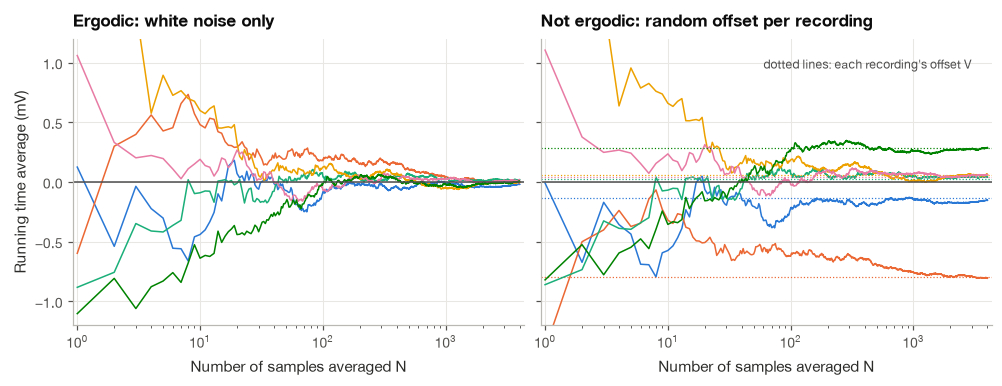

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for i in range(6):
    axes[0].semilogx(k_run, run_ergodic[i], color=C[i], lw=1)
    axes[1].semilogx(k_run, run_offset[i], color=C[i], lw=1)
    axes[1].axhline(V[i, 0], color=C[i], lw=0.8, ls=":")
for ax, title in zip(axes, ["Ergodic: white noise only", "Not ergodic: random offset per recording"]):
    ax.axhline(0, color="0.3", lw=1)
    ax.set(xlabel="Number of samples averaged N", title=title)
axes[0].set(ylabel="Running time average (mV)", ylim=(-1.2, 1.2))
axes[1].text(60, 0.95, "dotted lines: each recording's offset V", fontsize=8, color="0.3")
plt.show()

In the left panel every running average closes in on zero. In the right panel each one settles on its own dotted line. The practical lesson is that "averaging a long recording" and "averaging over subjects" answer different questions when there is variability between recordings, which is the situation in nearly every clinical study. Ergodicity is an assumption about the physics of the source, and I find it useful to ask, before trusting any time average, whether some hidden quantity is frozen for the whole recording.

(sec-7-1-5)=
## 7.1.5 White Noise, Colored Noise and Gaussian Processes

**White noise** is the simplest WSS process: zero mean, and uncorrelated at every nonzero lag,

(eq-7-7)=
\begin{equation*}
R_w[k] = \sigma_w^2\,\delta[k]. \tag{7.7}
\end{equation*}

The name will make sense in [Section 7.2](02_power_spectral_density.ipynb), where we show that its power is spread evenly over all frequencies, like white light. Amplifier thermal noise and the quantization noise of [Section 9.4](../ch09_sampling/index.md) are close to white within the bandwidth of a recording.

A process is **Gaussian** when every finite collection $x[n_1], \ldots, x[n_k]$ is jointly Gaussian. A multivariate Gaussian density is completely determined by its mean vector and covariance matrix, so a Gaussian process is completely determined by $\mu_x[n]$ and $C_x[n_1, n_2]$. One consequence is that for a Gaussian process wide-sense stationarity implies strict-sense stationarity: if the mean and covariance are shift invariant, so is every joint density built from them. This is part of the reason second-order methods (autocorrelation and power spectra) go so far with EEG and noise, whose amplitude histograms are often close to Gaussian.

**Colored noise** has correlation between neighboring samples. Physiological background activity is almost never white: the EEG is dominated by slow components, and muscle noise in an ECG has a characteristic band. The standard way to create colored noise is to pass white noise through a filter. The simplest case is the first-order **autoregressive** process, AR(1),

(eq-7-8)=
\begin{equation*}
x[n] = a\,x[n-1] + w[n], \qquad |a| < 1, \tag{7.8}
\end{equation*}

a recursive filter of the kind studied in Section 5.5, driven by white noise of variance $\sigma_w^2$.

**Step 1: the variance.** In steady state the process is WSS, so $\operatorname{Var}\{x[n]\} = \operatorname{Var}\{x[n-1]\} = \sigma_x^2$. The input $w[n]$ is independent of $x[n-1]$, which is built from earlier inputs only, so the variance of the sum in [(7.8)](#eq-7-8) is the sum of the variances:

$$
\sigma_x^2 = a^2\sigma_x^2 + \sigma_w^2 \quad\Longrightarrow\quad \sigma_x^2 = \frac{\sigma_w^2}{1 - a^2}.
$$

**Step 2: a recursion for the autocorrelation.** Multiply [(7.8)](#eq-7-8) by $x[n-k]$ for some $k \ge 1$ and take expectations:

$$
\mathbb{E}\{x[n]x[n-k]\} = a\,\mathbb{E}\{x[n-1]x[n-k]\} + \mathbb{E}\{w[n]x[n-k]\}.
$$

The left side is $R_x[k]$, the first term on the right is $a R_x[k-1]$, and the last term is zero because $x[n-k]$ depends only on inputs up to time $n - k < n$, all independent of $w[n]$. So $R_x[k] = a R_x[k-1]$.

**Step 3: solve the recursion.** Starting from $R_x[0] = \sigma_x^2$ and multiplying by $a$ at each step, then using even symmetry for negative lags,

(eq-7-9)=
\begin{equation*}
R_x[k] = \frac{\sigma_w^2}{1 - a^2}\,a^{|k|}. \tag{7.9}
\end{equation*}

The autocorrelation decays geometrically. With $a = 0.9$ it falls to $1/e$ of its peak after $-1/\ln 0.9 \approx 9.5$ samples, which at 160 Hz is about 60 ms: the process "remembers" its past for tens of milliseconds. A value of $a$ close to one gives slow, wandering noise; $a = 0$ gives white noise back.

In [9]:
def ar1(a, sigma_w, n_samples, rng, n_burn=500):
    """Simulate x[n] = a x[n-1] + w[n] (equation 12.8), discarding a burn-in transient."""
    w = rng.normal(0, sigma_w, n_samples + n_burn)
    x = np.zeros_like(w)
    for i in range(1, w.size):
        x[i] = a * x[i - 1] + w[i]
    return x[n_burn:]


def acorr_biased(x, max_lag):
    """Biased autocorrelation estimate (equation 12.10) for lags 0..max_lag."""
    N = x.size
    return np.array([np.dot(x[:N - k], x[k:]) / N for k in range(max_lag + 1)])


a, sw = 0.9, 1.0
x_ar = ar1(a, sw, 200_000, rng)
x_white = rng.normal(0, sw, 200_000)
lags = np.arange(0, 41)
R_ar_hat = acorr_biased(x_ar, lags[-1])
R_ar_theory = sw**2 / (1 - a**2) * a**lags

print(f"AR(1) variance: estimated {x_ar.var():.3f}, theory sigma_w^2/(1-a^2) = {sw**2 / (1 - a**2):.3f}")
for k in [1, 5, 10, 20]:
    print(f"R[{k:2d}]: estimated {R_ar_hat[k]:.3f}, theory {R_ar_theory[k]:.3f}")

AR(1) variance: estimated 5.203, theory sigma_w^2/(1-a^2) = 5.263
R[ 1]: estimated 4.679, theory 4.737
R[ 5]: estimated 3.054, theory 3.108
R[10]: estimated 1.802, theory 1.835
R[20]: estimated 0.633, theory 0.640


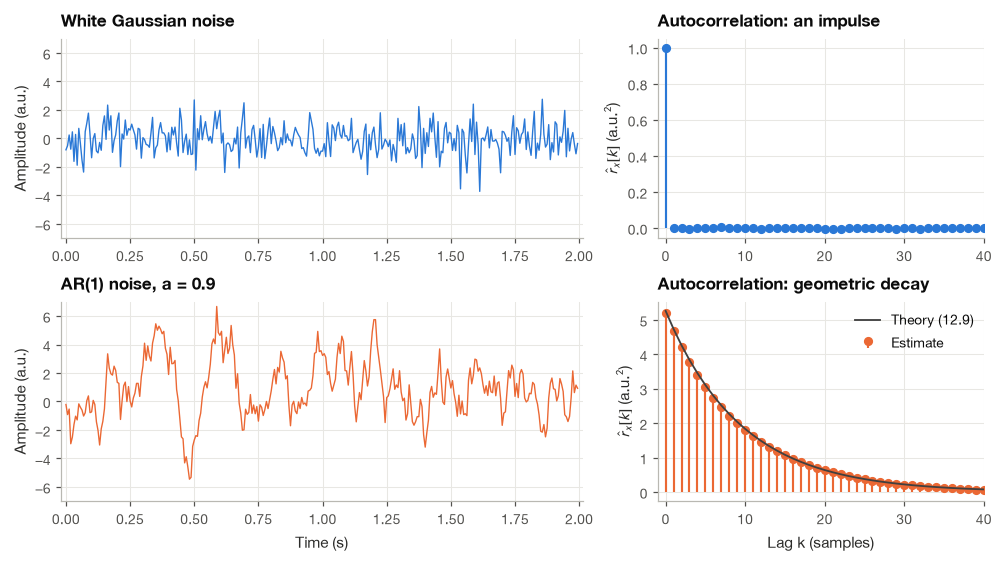

In [10]:
t_show = np.arange(320) / fs
fig, axes = plt.subplots(2, 2, figsize=(9, 5.0), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0, 0].plot(t_show, x_white[:320], color=C[0], lw=0.9)
axes[0, 0].set(ylabel="Amplitude (a.u.)", title="White Gaussian noise", ylim=(-7, 7))
axes[1, 0].plot(t_show, x_ar[:320], color=C[1], lw=0.9)
axes[1, 0].set(xlabel="Time (s)", ylabel="Amplitude (a.u.)", title="AR(1) noise, a = 0.9", ylim=(-7, 7))

R_white_hat = acorr_biased(x_white, lags[-1])
axes[0, 1].stem(lags, R_white_hat, linefmt=C[0], markerfmt="o", basefmt=" ")
axes[0, 1].set(ylabel=r"$\hat r_x[k]$ (a.u.$^2$)", title="Autocorrelation: an impulse")
axes[1, 1].stem(lags, R_ar_hat, linefmt=C[1], markerfmt="o", basefmt=" ", label="Estimate")
axes[1, 1].plot(lags, R_ar_theory, color="0.25", lw=1.2, label="Theory (12.9)")
axes[1, 1].set(xlabel="Lag k (samples)", ylabel=r"$\hat r_x[k]$ (a.u.$^2$)", title="Autocorrelation: geometric decay")
axes[1, 1].legend(loc="upper right")
for ax in axes[:, 1]:
    ax.set_xlim(-1, 40)
plt.show()

Both signals have independent Gaussian inputs, yet they look completely different. The AR(1) output is smoother because each sample carries 90% of the previous one; the white noise has no memory at all. Their autocorrelations make the difference precise.

(sec-7-1-6)=
## 7.1.6 Estimating the Autocorrelation from One Recording

Given $N$ samples $x[0], \ldots, x[N-1]$ of a zero-mean, ergodic WSS process, the natural estimate of $R_x[k]$ replaces the expectation by a time average over the available products. For lag $k \ge 0$ only $N - k$ products $x[n]x[n+k]$ exist, which leaves a choice of normalization:

(eq-7-10)=
\begin{equation*}
\hat{r}_x^{\,b}[k] = \frac{1}{N}\sum_{n=0}^{N-1-k} x[n]\,x[n+k], \qquad
\hat{r}_x^{\,u}[k] = \frac{1}{N - k}\sum_{n=0}^{N-1-k} x[n]\,x[n+k]. \tag{7.10}
\end{equation*}

**Bias.** Each product has expectation $R_x[k]$, and there are $N - k$ of them, so

(eq-7-11)=
\begin{equation*}
\mathbb{E}\{\hat{r}_x^{\,u}[k]\} = \frac{N - k}{N - k}R_x[k] = R_x[k], \qquad
\mathbb{E}\{\hat{r}_x^{\,b}[k]\} = \frac{N - k}{N}R_x[k] = \left(1 - \frac{k}{N}\right)R_x[k]. \tag{7.11}
\end{equation*}

The first estimator is unbiased; the second is biased toward zero by a triangular (Bartlett) factor that is negligible at small lags and severe near $k = N$.

**Variance.** The unbiased estimator pays for its correctness at large lags. When $k$ approaches $N$ it averages only a handful of products, and dividing by the small number $N - k$ amplifies their randomness instead of damping it. The biased estimator multiplies the same noisy sum by $(N-k)/N$, which shrinks the noise exactly where it is largest. Statisticians usually prefer the biased version for two reasons: its mean-squared error is generally smaller, and it is guaranteed to be a *positive semidefinite* sequence, which means its Fourier transform is never negative. That second property will matter in [Section 7.3](03_nonparametric_psd.ipynb), where the Fourier transform of $\hat{r}_x^{\,b}[k]$ turns out to be the periodogram, and in [Section 7.4](04_parametric_psd.ipynb), where the Yule–Walker equations need a valid autocorrelation matrix.

The experiment below draws 500 AR(1) records of only $N = 200$ samples each and compares the two estimators lag by lag.

In [11]:
def acorr_unbiased(x, max_lag):
    """Unbiased autocorrelation estimate (equation 12.10, right) for lags 0..max_lag."""
    N = x.size
    return np.array([np.dot(x[:N - k], x[k:]) / (N - k) for k in range(max_lag + 1)])


N_short, n_trials, max_lag = 200, 500, 190
lags_mc = np.arange(max_lag + 1)
est_b = np.empty((n_trials, max_lag + 1))
est_u = np.empty((n_trials, max_lag + 1))
for i in range(n_trials):
    x_i = ar1(a, sw, N_short, rng)
    est_b[i] = acorr_biased(x_i, max_lag)
    est_u[i] = acorr_unbiased(x_i, max_lag)

R_true = sw**2 / (1 - a**2) * a**lags_mc
check = acorr_biased(x_i, 5)
np_check = np.correlate(x_i, x_i, mode="full")[N_short - 1:N_short + 5] / N_short
print(f"From-scratch vs np.correlate (biased), max difference: {np.max(np.abs(check - np_check)):.1e}")
for k in [10, 50, 150]:
    print(f"k = {k:3d}: true {R_true[k]:6.3f} | biased mean {est_b[:, k].mean():6.3f}, "
          f"std {est_b[:, k].std():5.3f} | unbiased mean {est_u[:, k].mean():6.3f}, std {est_u[:, k].std():5.3f}")

From-scratch vs np.correlate (biased), max difference: 0.0e+00
k =  10: true  1.835 | biased mean  1.718, std 1.264 | unbiased mean  1.808, std 1.330
k =  50: true  0.027 | biased mean  0.040, std 0.986 | unbiased mean  0.053, std 1.315
k = 150: true  0.000 | biased mean  0.001, std 0.528 | unbiased mean  0.004, std 2.114


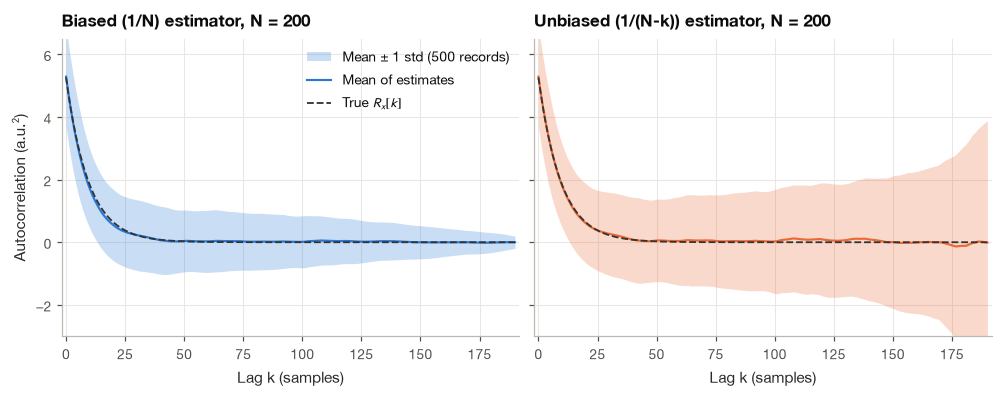

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, est, name, col in [(axes[0], est_b, "Biased (1/N)", C[0]), (axes[1], est_u, "Unbiased (1/(N-k))", C[1])]:
    m, s = est.mean(axis=0), est.std(axis=0)
    ax.fill_between(lags_mc, m - s, m + s, color=col, alpha=0.25, lw=0, label="Mean ± 1 std (500 records)")
    ax.plot(lags_mc, m, color=col, label="Mean of estimates")
    ax.plot(lags_mc, R_true, color="0.2", ls="--", lw=1.2, label="True $R_x[k]$")
    ax.set(xlabel="Lag k (samples)", title=f"{name} estimator, N = {N_short}")
axes[0].set(ylabel="Autocorrelation (a.u.$^2$)", ylim=(-3, 6.5))
axes[0].legend(loc="upper right")
plt.show()

The numbers tell the story. At lag 10 the biased estimator averages 1.72 against a true value of 1.84, close to the prediction $(1 - 10/200) \times 1.84 = 1.74$ of equation [(7.11)](#eq-7-11), while the unbiased estimator is centered correctly. Notice, though, that both have a standard deviation of about 1.3 at this lag: with only 200 samples, a single estimate is far less reliable than the smooth mean curves suggest. At large lags the picture reverses. The true autocorrelation at lag 150 is essentially zero, and both estimators are centered there, but the unbiased one scatters with a standard deviation of 2.1, four times that of the biased one, and its band in the right panel flares open as $N - k$ shrinks. My rule of thumb is to trust autocorrelation estimates only up to lags of about $N/10$, and to use the biased form whenever the estimate feeds into a spectrum or a model.

```{important}
Both estimators in (12.10) assume a zero-mean process. Real recordings have offsets (Section 12.1.4) and drift, so always subtract the sample mean (or detrend) first. Otherwise the squared mean adds a constant to every lag and the estimate never decays.
```

(sec-7-1-7)=
## 7.1.7 Is the EEG Stationary? A Check on Real Data

Every spectral method in the rest of this chapter assumes, at least approximately, a WSS process. The ECG is clearly not stationary in that sense: its statistics repeat with every heartbeat, which makes it *cyclostationary*, and for heart rate variability the convention is instead to treat the sequence of RR intervals as a stationary process over windows of a few minutes (Section 19.2). The EEG is the textbook example of a signal analyzed as if it were stationary, so I want to test that assumption directly. The recording is run R01 of subject S001 from the EEG Motor Movement/Imagery Dataset {cite:p}`schalk2004,goldberger2000`: one minute of resting EEG with the eyes open, sampled at 160 Hz.

### Step 1: Load the recording and pick a channel

We use the midline occipital electrode Oz, over the visual cortex. MNE returns volts, so we convert to µV, and we keep the first 60 s (the last fraction of a second of this file is flat).

In [13]:
raw = mne.io.read_raw_edf("../data/eegmmidb/S001R01.edf", preload=True)
mne.datasets.eegbci.standardize(raw)
fs_eeg = raw.info["sfreq"]
eeg = raw.get_data(picks=["Oz"])[0, : int(60 * fs_eeg)] * 1e6     # µV
t_eeg = np.arange(eeg.size) / fs_eeg
print(f"Oz: {eeg.size} samples at {fs_eeg:.0f} Hz, mean {eeg.mean():.1f} µV, std {eeg.std():.1f} µV")

Oz: 9600 samples at 160 Hz, mean -1.2 µV, std 51.5 µV


### Step 2: Cut it into segments and compute statistics per segment

If the process were stationary and ergodic, every 2 s piece would be a smaller sample from the same distribution, and its mean, standard deviation and short-lag autocorrelation would differ only by sampling error. We compute, for each of the 30 segments, the mean, the standard deviation, and the normalized autocorrelation at a lag of 25 ms (four samples).

In [14]:
seg_len = int(2 * fs_eeg)
segments = eeg.reshape(-1, seg_len)
seg_mean = segments.mean(axis=1)
seg_std = segments.std(axis=1)
seg_rho = np.array([acorr_biased(s - s.mean(), 4)[4] / s.var() for s in segments])

stats = pd.DataFrame({"mean (µV)": seg_mean, "std (µV)": seg_std, "rho at 25 ms": seg_rho})
print(stats.describe().loc[["mean", "std", "min", "max"]].round(2))

      mean (µV)  std (µV)  rho at 25 ms
mean      -1.20     46.95          0.54
std       18.21     11.53          0.16
min      -28.17     31.22          0.05
max       60.60     84.80          0.79


### Step 3: How much scatter would a stationary process produce?

A spread of segment statistics is expected even for a perfectly stationary process, because 2 s is a short sample. To judge whether the spread we see is *too large*, we need a reference. I use **phase-randomized surrogates**: we take the DFT of the whole minute, keep every magnitude, replace every phase by a random one and transform back. The surrogate has the same periodogram as the EEG, and hence (as [Section 7.3](03_nonparametric_psd.ipynb) will show) the same estimated autocorrelation, but any slow change in the signal's character has been scrambled away. It is a stationary process with the EEG's second-order statistics. We compare the coefficient of variation (std divided by mean) of the 30 segment variances.

In [15]:
def phase_randomize(x, rng):
    """Surrogate with the same DFT magnitudes as x and uniformly random phases."""
    X = np.fft.rfft(x)
    phases = np.exp(1j * rng.uniform(0, 2 * np.pi, X.size))
    phases[0] = 1.0                      # keep the mean real
    phases[-1] = 1.0                     # keep the Nyquist bin real (even length)
    return np.fft.irfft(X * phases, n=x.size)


def cv_of_segment_variance(x, seg_len):
    v = x.reshape(-1, seg_len).var(axis=1)
    return v.std() / v.mean()


cv_eeg = cv_of_segment_variance(eeg, seg_len)
cv_surr = np.array([cv_of_segment_variance(phase_randomize(eeg, rng), seg_len) for _ in range(300)])
print(f"CV of 2 s segment variance, real EEG          : {cv_eeg:.2f}")
print(f"CV, 300 stationary surrogates (mean, 95th pct): {cv_surr.mean():.2f}, {np.percentile(cv_surr, 95):.2f}")
print(f"Fraction of surrogates at least as variable   : {np.mean(cv_surr >= cv_eeg):.3f}")

CV of 2 s segment variance, real EEG          : 0.55
CV, 300 stationary surrogates (mean, 95th pct): 0.29, 0.36
Fraction of surrogates at least as variable   : 0.000


### Step 4: Look at the result

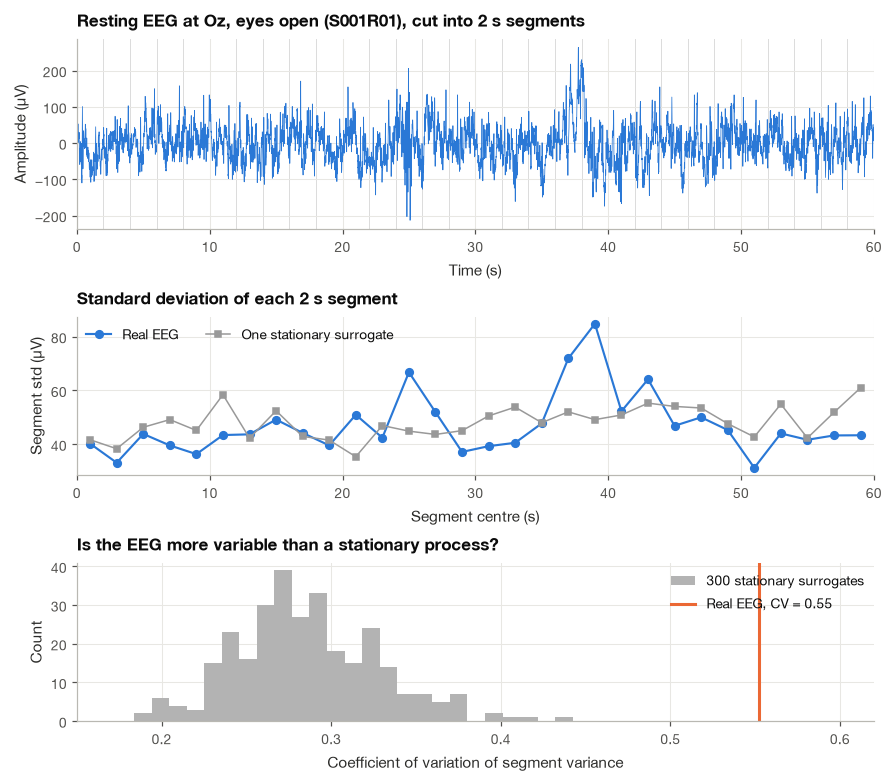

In [16]:
seg_t = (np.arange(segments.shape[0]) + 0.5) * 2
fig, axes = plt.subplots(3, 1, figsize=(8, 7.0), gridspec_kw={"height_ratios": [1.2, 1, 1]})
ax = axes[0]
ax.plot(t_eeg, eeg, color=C[0], lw=0.5)
for edge in np.arange(0, 61, 2):
    ax.axvline(edge, color="0.85", lw=0.6, zorder=0)
ax.set(xlabel="Time (s)", ylabel="Amplitude (µV)", xlim=(0, 60),
       title="Resting EEG at Oz, eyes open (S001R01), cut into 2 s segments")

ax = axes[1]
surr = phase_randomize(eeg, rng)
ax.plot(seg_t, seg_std, "o-", color=C[0], label="Real EEG")
ax.plot(seg_t, surr.reshape(-1, seg_len).std(axis=1), "s-", color="0.6", ms=4, lw=1,
        label="One stationary surrogate")
ax.set(xlabel="Segment centre (s)", ylabel="Segment std (µV)", xlim=(0, 60),
       title="Standard deviation of each 2 s segment")
ax.legend(loc="upper left", ncols=2)

ax = axes[2]
ax.hist(cv_surr, bins=25, color="0.7", label="300 stationary surrogates")
ax.axvline(cv_eeg, color=C[1], lw=2, label=f"Real EEG, CV = {cv_eeg:.2f}")
ax.set(xlabel="Coefficient of variation of segment variance", ylabel="Count", xlim=(0.15, 0.62),
       title="Is the EEG more variable than a stationary process?")
ax.legend(loc="upper right")
plt.show()

### Step 5: Interpret

The segment standard deviations wander between roughly 30 and 85 µV, the normalized autocorrelation at 25 ms ranges from 0.05 to 0.79 (so even the *shape* of the correlation, not just the scale, changes between segments), and two stretches stand out: a burst near 24–26 s and a slow excursion around 36–40 s (both visible in the top trace, probably small movements or eye-related artifacts). The segment means swing by tens of microvolts as well, which is slow drift of the kind the random walk illustrated. The surrogate test makes the conclusion quantitative: none of the 300 stationary surrogates is as variable as the real EEG. Over a full minute, this resting EEG is **not** wide-sense stationary.

That does not make spectral analysis hopeless. Within a single 2 s segment the signal looks statistically homogeneous, and its character changes only gradually from one segment to the next, apart from occasional artifacts. Signals of this kind are called **locally stationary**: stationary enough over a short window to justify second-order analysis, nonstationary over longer spans. The practical consequences shape the next sections. We estimate spectra from short windows and average them (Welch's method, [Section 7.3](03_nonparametric_psd.ipynb)), we prefer methods that work with little data when windows must be short (autoregressive models, [Section 7.4](04_parametric_psd.ipynb)), and when the change itself is the object of interest we move to time–frequency analysis (Chapter 23). Artifact rejection before averaging, which removes segments like the one at 25 s, follows from the same reasoning.

## Summary

A random process assigns a whole signal to each outcome of a random experiment, so it can be read across the ensemble at a fixed time or along one realization. For signal processing the essential description is second order: the mean function and the autocorrelation function $R_x[n_1, n_2] = \mathbb{E}\{x[n_1]x[n_2]\}$. A process is wide-sense stationary when the mean is constant and the autocorrelation depends only on the lag; the autocorrelation is then even, peaks at lag zero, and $R_x[0]$ is the mean power. Ergodicity is what licenses replacing ensemble averages by time averages, and we derived the variance of the time average [(7.6)](#eq-7-6) to see when that works and why a random per-recording offset breaks it. White noise has an impulse for its autocorrelation; filtering it produces colored noise, and the AR(1) process gave a closed-form geometric autocorrelation [(7.9)](#eq-7-9). Estimating $R_x[k]$ from data involves a trade between the unbiased estimator and the lower-variance, positive semidefinite biased estimator. A real resting EEG turned out to be only locally stationary.

The next section takes the Fourier transform of the autocorrelation and arrives at the power spectral density, the frequency-domain description of a random process. Sections 7.3 and 12.4 then turn the ideas of this section (finite records, bias and variance, short stationary windows) into practical spectral estimators, which reappear in heart rate variability (Section 19.2) and EEG analysis ([Section 13.2](../ch20_eeg/index.md)).

## Exercises

1. Let $x[n] = B\cos(\Omega_0 n)$, where $B$ is a zero-mean random variable with variance $\sigma_B^2$ and $\Omega_0$ is fixed. Compute $\mu_x[n]$ and $R_x[n_1, n_2]$. Is the process wide-sense stationary? Compare with the random-phase sinusoid of Example 7.1.1.
2. Show that if $x[n]$ is WSS with mean $\mu_x$, then $R_x[k] = C_x[k] + \mu_x^2$. Use this to explain the warning in the {important} box of [Section 7.1.6](#sec-7-1-6): what does the biased estimate of the autocorrelation of an un-detrended EEG with a 30 µV offset look like?
3. For the AR(1) process [(7.8)](#eq-7-8), derive $R_x[k]$ for $a < 0$ and sketch it. What kind of signal has an autocorrelation that alternates in sign? Simulate $a = -0.8$ and verify [(7.9)](#eq-7-9).
4. Use equation [(7.6)](#eq-7-6) to compute $\operatorname{Var}\{\hat{\mu}_N\}$ for the AR(1) process with $a = 0.9$ and $N = 1000$, and compare it with the white-noise value $\sigma_x^2/N$ for the same variance $\sigma_x^2$. Interpret the ratio as an "effective number of independent samples," and check it with a Monte Carlo simulation.
5. Repeat the stationarity check of [Section 7.1.7](#sec-7-1-7) with segment lengths of 1, 4 and 8 s, and on the eyes-closed run S001R02. Does the conclusion depend on the segment length? Why does the surrogate distribution itself change with the segment length?
6. (Harder.) The random walk is not stationary, but its first difference $s[n] - s[n-1]$ is. Load 60 s of the baseline-wander noise record `bw` from `../data/nstdb/` and compare the segment-variance test of [Section 7.1.7](#sec-7-1-7) applied to the record and to its first difference. What does this suggest about how to make a drifting physiological signal approximately stationary?

## Further Reading

{cite:t}`papoulis2002` is the classic reference for random processes, with careful treatments of stationarity, ergodicity and Gaussian processes. {cite:t}`bendat2010` approaches the same material from the measurement side and is especially good on estimation errors for correlation functions and on testing stationarity. For biomedical signals, {cite:t}`sornmo2005` (Chapter 3) discusses stationarity of the EEG and the modeling of background activity, and {cite:t}`rangayyan2015` gives many examples of nonstationary physiological signals.